# WASP-43 b with MIRI/LRS: a full-orbit phase curve

WASP-43 b is a hot Jupiter on a 19.5-hour orbit around a K7 dwarf. ERS
programme 1366 observed one complete orbit with the MIRI low-resolution
spectrometer in slitless mode: two eclipses, one transit and the phase
variation in between (Bell et al. 2024, Nature Astronomy 8, 879). The
dayside reaches ~1500 K, and the nightside flux constrains the clouds there.

This tutorial covers what is specific to MIRI and to phase curves:

* the MIRI Stage 1 recipe, and why it now follows the official
  time-series configuration (the `rscd` step changed the transit depth by
  55 ppm);
* a visit split into **three exposures**, and why the extraction then fits
  **one PSF for the whole visit** (per-exposure PSFs put flux steps of up to
  2.5 ppt at the exposure boundaries);
* the change of the LRS wavelength calibration in 2024, which matters when
  comparing with published band-integrated numbers;
* a phase-curve fit with juliet and the comparison with the four published
  reductions.

**Contents**

1. The data
2. Stage 1 (one segment) and the start of the MIRI ramps
3. Stage 2, cleaning, extraction (one segment)
4. The full visit: three exposures, one PSF
5. Phase-curve fit
6. Comparison with Bell et al. (2024)
7. Summary

## 1. The data

| | |
| --- | --- |
| Programme | JWST ERS 1366, observation 11 (1-2 December 2022) |
| Mode | MIRI LRS slitless, SLITLESSPRISM, FASTR1 |
| Integrations | 3 exposures × 3072 integrations of 64 groups (10.34 s each), 10 segments per exposure |
| Duration | 26.5 h |
| Files | `jw01366011001_04103_0000[1-3]-seg0[01-10]_mirimage_uncal.fits` (about 42 GB) |

```python
from astroquery.mast import Observations

obs = Observations.query_criteria(obs_collection='JWST', proposal_id='1366',
                                  instrument_name='MIRI/SLITLESS')
prods = Observations.filter_products(Observations.get_product_list(obs),
                                     productSubGroupDescription='UNCAL')
keep = [f.startswith('jw01366011001_04103') for f in prods['productFilename']]
Observations.download_products(prods[keep], download_dir=DATA, flat=True)
```

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

from jstark.reduction import Stage1, Stage2, ExposureCleaner
from jstark.reduction import diagnostics as rdiag
from jstark.extraction import SpectralExtractor, VisitExtractor, Spectra
from jstark.extraction import diagnostics as xdiag
from jstark.fitting import LightCurves, BroadbandFit

DATA = '/Volumes/Jayshil SSD/JWST/jwst-ers/Data/MIRI'          # the uncal files
TUT = os.path.join(DATA, 'tutorial')                          # one segment (this notebook)
FULL = os.path.join(DATA, 'reduction', 'rscdoff')             # full visit, current defaults
EXPOSURES = ['_00001', '_00002', '_00003']
ROOT = 'jw01366011001_04103{}_mirimage'
RUN_FULL = False

plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80})
os.makedirs(TUT, exist_ok=True)

## 2. Stage 1

The folder holds three exposures; `exposure=` selects one. The MIRI recipe
is the official time-series configuration plus jstark's
`consistent_saturation` and `temporal_jump`.

In [2]:
s1 = Stage1(DATA, outdir=TUT, exposure='_00001')
s1.set('ramp_fit', maximum_cores='4')
s1.show()

jstark Stage1: MIRI/LRS | exposure jw01366011001_04103_00001_mirimage | 10 segment(s) | output -> /Volumes/Jayshil SSD/JWST/jwst-ers/Data/MIRI/tutorial
Recipe for MIRI/LRS:
   0. [run ] jwst   group_scale          
   1. [run ] jwst   dq_init              
   2. [run ] jwst   emicorr              
   3. [run ] jwst   saturation           
   4. [run ] jstark consistent_saturation {'min_frac': 0.01, 'scope': 'exposure'}
   5. [SKIP] jwst   firstframe           {'bright_use_group1': True}
   6. [run ] jwst   lastframe            
   7. [run ] jwst   reset                
   8. [run ] jwst   linearity            
   9. [SKIP] jwst   rscd                 
  10. [run ] jwst   dark_current         
  11. [SKIP] jwst   refpix               
  12. [SKIP] jstark group_bkg            {'method': 'median', 'axis': 'row'}
  13. [SKIP] jwst   jump                 {'rejection_threshold': 15.0, 'maximum_cores': 'half'}
  14. [run ] jstark temporal_jump        {'window': 11, 'threshold': 10.0, 'mode': 

Compared with the near-infrared detectors:

* `emicorr` removes the electromagnetic interference pattern of the MIRI
  read-out;
* `lastframe` flags the last group (affected by the reset of the next
  integration), `reset` corrects the reset anomaly, and `dark_current`
  runs;
* `firstframe`, `rscd` and `refpix` are skipped, as in the official
  pipeline for time series (CRDS `pars-detector1pipeline` with
  `TSOVISIT=True`), and there is no group-level 1/f step.

### 2.1 The start of the MIRI ramps

MIRI ramps are not linear at their start: the first group differences of
each integration are too large (the reset switch charge decay, RSCD). We
stop Stage 1 after `dark_current` and look at the summed group differences
of the brightest pixels.

  saturation pre-pass: segment 1/10
  saturation map: 90 pixels saturate (in >= 1% of integrations); first saturated group histogram [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 9, 0, 0, 9, 0, 0, 9, 0, 0, 0, 0, 9, 0, 0, 9, 0, 0, 0, 0, 0, 9, 0, 9, 0, 9, 9, 0, 0, 29862]
Segment 1/10: jw01366011001_04103_00001-seg001_mirimage_uncal.fits


    group_scale          done in    0.3 s


    dq_init              done in    0.5 s


    emicorr              done in   30.1 s


    saturation           done in    4.0 s


    consistent_saturation: 90 pixels, 397782 saturated-group flags added
    consistent_saturation done in    0.7 s


    lastframe            done in    0.3 s


    reset                done in    0.4 s


    linearity            done in    1.4 s


    dark_current         done in    0.8 s


group  1: 1.282
group  2: 1.177
group  4: 1.073
group  8: 1.019
group 12: 1.010
CPU times: user 1min 10s, sys: 6.35 s, total: 1min 16s
Wall time: 1min 20s


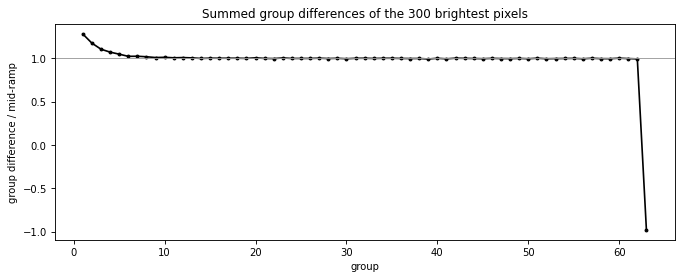

In [3]:
%%time
s1.compute_saturation_map(segments=[0])
ramp = s1.run(segments=[0], stop='dark_current')

d = ramp.data                                   # (integrations, groups, rows, columns)
sig = np.nanmedian(d[:, -3] - d[:, 3], axis=0)
good = (ramp.pixeldq & 1) == 0                  # not DO_NOT_USE
idx = np.argsort(np.where(good, sig, -np.inf).ravel())[-300:]        # 300 brightest pixels
rows, cols = np.unravel_index(idx, sig.shape)
diffs = np.diff(d[:, :, rows, cols], axis=1).sum(axis=2)             # (integrations, groups - 1)
prof = np.nanmedian(diffs[1:], axis=0)                               # integrations 2 onwards
prof = prof / np.median(prof[20:50])

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.arange(1, len(prof) + 1), prof, 'k.-')
ax.axhline(1, color='0.6', lw=0.8)
ax.set_xlabel('group'); ax.set_ylabel('group difference / mid-ramp')
ax.set_title('Summed group differences of the 300 brightest pixels')
for g in (1, 2, 4, 8, 12):
    print(f'group {g:2d}: {prof[g - 1]:.3f}')

The first group differences are tens of per cent too large; from about
group 12 the ramp is linear to ~1%. (The MIRI dark adds a fixed pattern of
1-3% to the group differences, the same in every integration.) The question
is whether to fit these early groups.

<div class="alert alert-info">

**Why the early groups are fitted (rscd skipped)**

In jwst 3.0 the `rscd` step no longer corrects the early groups: it flags
them as DO_NOT_USE (for SLITLESSPRISM FASTR1, 5 groups in the first
integration and 7 in later ones). The ramp fit then starts at group 8.

jstark first ran `rscd`. Against the official Stage 1, which skips it, the
WASP-43 b transit came out **55 ± 11 ppm deeper**, and changing the other
steps one at a time (`firstframe`, the jump algorithm,
`consistent_saturation`) moved the depth by at most 7 ppm. Including the
early groups raises the rates by a slightly flux-dependent fraction
(official / ours 1.014 at 50-100 DN/s, 1.009 above 1000 DN/s), and that
non-proportional response changes the transit depth.

Which depth is right cannot be decided from these data alone. On the
photometric GJ 3929 data, starting the ramp later only rescaled the flux by
~0.3% and cost precision (740 → 944 ppm from group 0 to group 12). Since
the official pipeline and the published reductions (e.g. Bell et al.'s
Eureka! v1) fit the early groups, jstark now does the same: `firstframe`,
`rscd` and `refpix` are skipped. This also lowers the white-light noise by
5.6%. To start the ramp later, use `s1.set('ramp_fit', firstgroup=8)`.

</div>

Segment 1/10: jw01366011001_04103_00001-seg001_mirimage_uncal.fits


    temporal_jump: 10111 jumps (flag), median fraction of pixels hit per integration = 0.090%
    temporal_jump        done in   67.0 s


    ramp_fit             done in   16.5 s
    gain_scale           done in    0.1 s


  -> /Volumes/Jayshil SSD/JWST/jwst-ers/Data/MIRI/tutorial/jw01366011001_04103_00001-seg001_mirimage_rateints.fits  (83.9 s)
CPU times: user 1min 3s, sys: 5.88 s, total: 1min 9s
Wall time: 1min 24s


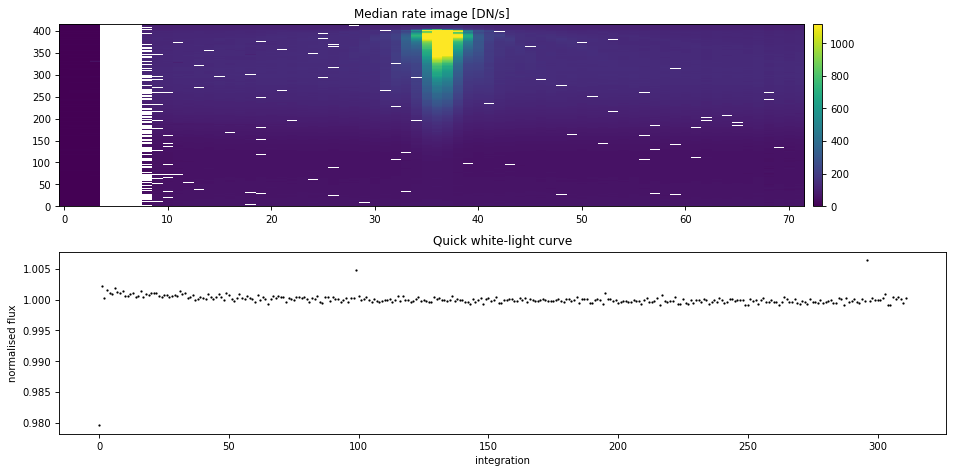

In [4]:
%%time
rateints = s1.run(segments=[0], start='temporal_jump', model=ramp)
rdiag.plot_rateints(rateints[0]);

## 3. Stage 2, cleaning and extraction (one segment)

The LRS disperses along the detector rows (wavelength changes with the row),
so jstark transposes MIRI/LRS data internally: in the extraction, a
"column" is a detector row. `Stage2` evaluates the slitless wavelength
solution.

Wavelength map (416, 72): 4.064-14.050 micron
Saved wavelength map to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/MIRI/tutorial/jw01366011001_04103_00001_mirimage_wavelength.fits


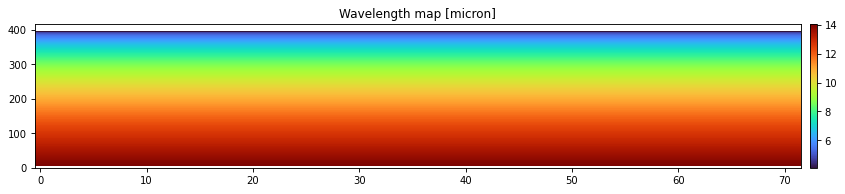

In [5]:
wfile = Stage2(TUT).run()['wavelength']
wave = fits.getdata(wfile, 'WAVELENGTH')
rdiag.plot_wavelength(wave);

<div class="alert alert-info">

**The LRS wavelength calibration changed in 2024**

The MIRI LRS slitless wavelength solution was replaced in August/September
2024 (CRDS `specwcs_0006` → `specwcs_0015`). At the detector row that the
old solution called 5.000 µm the new one gives 5.174 µm (6.0 → 6.083,
7.0 → 7.026, 8.0 → 7.995, 10.5 → 10.488 µm). Bell et al. (2024) used the old
solution, so their "5-10.5 µm" white light is **5.174-10.488 µm** in
current wavelengths. The bluest columns carry a third of the white-light
flux at the lowest planet-star contrast: with 5-10.5 µm in current
wavelengths the dayside flux came out 106 ppm below Bell's, in the matched
band 48 ppm. Convert band edges before comparing with papers that predate
the change.

</div>

MIRI data have a significant background, so the cleaner also subtracts it
from every integration (`background=True`: per row, the median of the
background pixels). The extraction then uses the 5-12 µm default range:
below ~4.5 µm the prism dispersion folds back (several wavelengths fall on
the same pixels), 5-6 µm receives some shorter-wavelength light, and beyond
12 µm the throughput is low.

ExposureCleaner: MIRI/LRS | jw01366011001_04103_00001_mirimage | 1 segment(s), 312 integrations


  pass 1: segment 1/1 read
compute_global: 3764 bad pixels from DQ, 7 hot/noisy pixels; trace mask 25.2% of pixels


  segment 1/1: 3287 transient flags (10.5 per integration) -> jw01366011001_04103_00001-seg001_mirimage_cleaned.fits
Saved exposure info to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/MIRI/tutorial/jw01366011001_04103_00001_mirimage_cleaninfo.fits
SpectralExtractor: MIRI/LRS | jw01366011001_04103_00001_mirimage | 1 segment(s), 312 integrations | orders [1]
MIRI/LRS | orders [1]
  columns     columns=None, wavelength_range=(5.0, 12.0), snr_min=5.0, min_good_frac=0.5, gap=5
  trace       halfwidth=None, nknots=8, clip=3.0, reference=None, ref_order=1
  background  method=median, inner=10.0, outer=None, nsigma=3.0, maxiters=3, poly_order=1, min_pixels=10
  psf         halfwidth=7.0, oversample=2.0, knot_col=15, smooth=cv, clip=6.0, init_ints=200, ints=all, second_pass=False, pixel_correction=True, cv=phase
  extract     method=optimal, aperture=5.0, variance=mean, reject=6.0, reject_iters=3, reject_mode=temporal, fit_background=False, refine_shift=2, joint_iters=3, max_maskfrac=0.98, min_grou

  order 1: first PSF from 200 integrations; residual scale 1.00 sigma; 0.004% of pixels rejected


  order 1: PSF pass 1: 1070552 pixels from 312 integrations, 589 coefficients, smoothing (u, x) = (2e-06, 2e-03), reduced chi2 1.674, rejected 0.004%
  pixel-response map: 3436 pixels, rms 0.0186
fit_psf done in 2 s


  segment 1/1: 312 integrations; order 1: 0.4 rejected px/int, dy rms 3.3 mpx
extraction done in 2 s
Saved spectra to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/MIRI/tutorial/jw01366011001_04103_00001_mirimage_spectra.fits


CPU times: user 13.6 s, sys: 13.5 s, total: 27.1 s
Wall time: 8.99 s


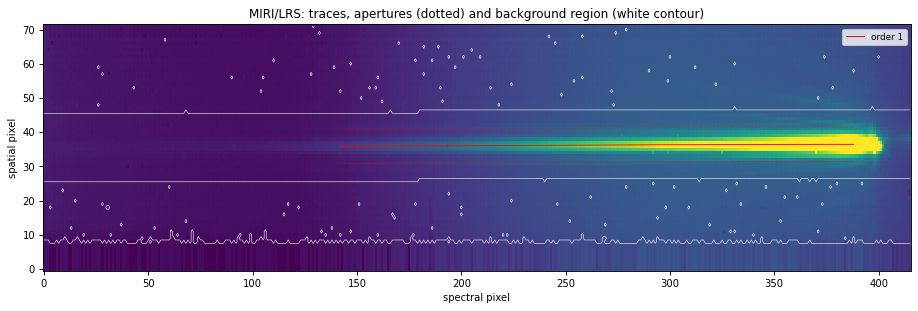

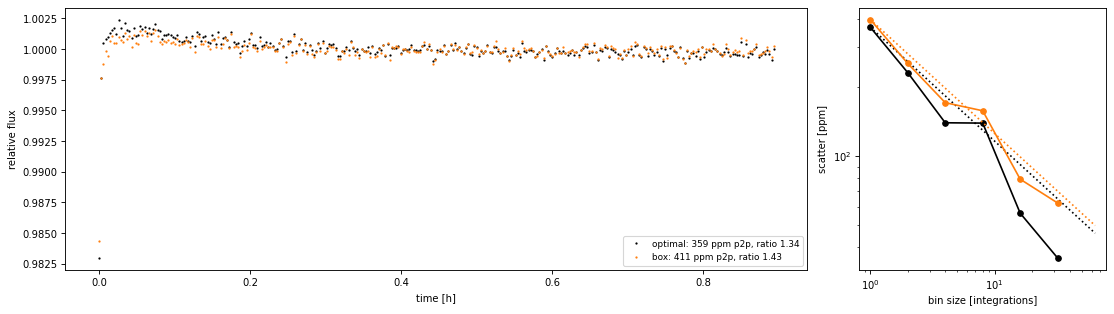

In [6]:
%%time
info = ExposureCleaner(TUT, wavelength=wfile).run(background=True)
ex = SpectralExtractor(info)
ex.show()
ex.find_trace()
ex.fit_psf()
spec1 = ex.run()
xdiag.plot_trace(ex)
xdiag.plot_white_light(spec1);

## 4. The full visit: three exposures, one PSF

The three exposures are reduced one at a time (Stage 1 and cleaning take
about 27 minutes per exposure here), and then extracted together with
`VisitExtractor`. It fits **one** PSF and pixel-response map from the
integrations of all three exposures; each exposure keeps its own trace,
background and output file.

In [7]:
if RUN_FULL:
    infos = []
    for e in EXPOSURES:
        s1 = Stage1(DATA, outdir=os.path.join(FULL, 'stage1'), exposure=e)
        s1.set('ramp_fit', maximum_cores='4')
        s1.run(save_variances=False)
        wf = Stage2(os.path.join(FULL, 'stage1'), exposure=e).run()['wavelength']
        infos.append(ExposureCleaner(os.path.join(FULL, 'stage1'), outdir=FULL, exposure=e,
                                     wavelength=wf).run(background=True))
    vx = VisitExtractor(infos, outdir=FULL)
    vx.find_trace()
    vx.fit_psf()                     # one PSF from all 9216 integrations (32 s)
    vx.run(keep_segments=False)

Why one PSF? The first reduction fitted a PSF per exposure (the
`SpectralExtractor` default for a single exposure). The comparison below
uses an earlier reduction in which the same Stage 1 products were
extracted both ways: per exposure (`reduction/`) and with one visit PSF
(`reduction/visitpsf/`). We measure the flux step at each exposure boundary
from straight lines fitted to 300 integrations on each side.

In [8]:
def visit_lc(folder, method):
    files = [os.path.join(folder, ROOT.format(e) + '_spectra.fits') for e in EXPOSURES]
    lcs = [LightCurves.from_spectra(f, method=method, name='LRS').select_channels(wave_range=(5.174, 10.488))
           for f in files]
    return LightCurves.concatenate(lcs, common_channels=True)

def boundary_steps(lc, n=300, skip=30):
    f, _ = lc.white_light()
    steps = []
    for e0, _ in lc.meta['exposures'][1:]:
        before = np.arange(e0 - n, e0)
        after = np.arange(e0 + skip, e0 + skip + n)
        pb = np.polyfit(lc.times[before], f[before], 1)
        pa = np.polyfit(lc.times[after], f[after], 1)
        t = 0.5 * (lc.times[e0 - 1] + lc.times[e0])
        steps.append(1e3 * (np.polyval(pa, t) - np.polyval(pb, t)))
    return steps

R = os.path.join(DATA, 'reduction')
for name, folder in (('PSF per exposure', R), ('one PSF per visit', os.path.join(R, 'visitpsf'))):
    for method in ('optimal', 'box'):
        s = boundary_steps(visit_lc(folder, method))
        print(f'{name:18s} {method:8s} steps: ' + ', '.join(f'{x:+.2f} ppt' for x in s))

PSF per exposure   optimal  steps: -2.08 ppt, +0.16 ppt
PSF per exposure   box      steps: -0.13 ppt, -0.13 ppt


one PSF per visit  optimal  steps: -0.11 ppt, -0.08 ppt
one PSF per visit  box      steps: -0.12 ppt, -0.13 ppt


<div class="alert alert-info">

**Why one PSF per visit**

The optimal flux scales with the profile. A PSF fitted to one exposure
differs from one fitted to another by its own fitting noise (here ~1% in
the profile), and that rescales each exposure's flux: a step of about −2 ppt
at the first boundary (above), where the box flux, which does not use the
profile, shows only a small one. Background, trace position and
pixel-response map were the same between exposures to < 0.1 ppt. A
phase-curve fit absorbed the steps into the phase curve (nightside 243 ppm
instead of ~1600). With one PSF for the visit, the optimal flux has the
same steps as the box flux, and no step term is needed in the fit (the
evidence prefers the model without one).

</div>

## 5. Phase-curve fit

The three exposures are joined into one dataset with
`LightCurves.concatenate` (one baseline for the visit; the white light is the
sum of the columns in Bell et al.'s band). As in Bell et al.'s fiducial
fit, the first 779 integrations are removed (plus 30 after each exposure
boundary), and the systematics are one exponential ramp and a linear model
in time, trace position `dy` and PSF width `ds`; 5σ outliers are clipped
(this removes the two high-gain-antenna moves). The planet is a transit
(free $R_p/R_*$, $a/R_*$, $b$, $t_0$, quadratic limb darkening) and a
second-order Cowan & Agol (2008) phase curve with a free eclipse time.

In [9]:
fit_dir = os.path.join(DATA, 'reduction', 'fits', 'white_pc_o2_trim30_rscdoff_w5.174-10.488')
if RUN_FULL:
    P = 0.813474062
    lc = visit_lc(FULL, 'optimal')
    lc = lc.exclude(ints=[(0, 779)] + [(e0, e0 + 30) for e0, _ in lc.meta['exposures'][1:]])
    tg = 2459915.1208                                  # transit time (guess)
    pri = {'P_p1': ('fixed', P), 't0_p1': ('normal', [tg, 0.01]),
           'a_p1': ('uniform', [3., 7.]), 'b_p1': ('uniform', [0., 1.]),
           'ecc_p1': ('fixed', 0.), 'omega_p1': ('fixed', 90.), 'p_p1': ('uniform', [0.1, 0.2]),
           'q1_LRS': ('uniform', [0., 1.]), 'q2_LRS': ('uniform', [0., 1.]),
           't_secondary_p1': ('normal', [tg + P / 2, 10. / 1440.]),
           'fp_p1': ('uniform', [0., 0.012]),
           'C1_p1': ('uniform', [-0.01, 0.01]), 'D1_p1': ('uniform', [-0.01, 0.01]),
           'C2_p1': ('uniform', [-0.005, 0.005]), 'D2_p1': ('uniform', [-0.005, 0.005])}
    fit = BroadbandFit({'LRS': lc}, priors=pri, out_folder=fit_dir,
                       linear=['time', 'dy', 'ds'], ramp=1, clip={'nsigma': 5, 'window': 31})
    fit.fit(nthreads=8)                               # 6 min
fit = BroadbandFit.load(fit_dir)
s = fit.summary()
s[[n.startswith(('t0', 'a_p1', 'b_p1', 'depth', 'fp_p1_ppm', 'fnight', 'pcamp', 'pcoffset', 't_sec'))
   for n in s['name']]]

Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/jwst-ers/Data/MIRI/reduction/fits/white_pc_o2_trim30_rscdoff_w5.174-10.488/_dynesty_DNS_posteriors.pkl


name,median,err_plus,err_minus,kind
str15,float64,float64,float64,str7
t0_p1,2459915.1207878077,1.2056436389684677e-05,1.1863186955451965e-05,fitted
a_p1,4.892982789942763,0.012284190050327659,0.012049887422512562,fitted
b_p1,0.6547628771371079,0.002774448783351202,0.0027980440707987553,fitted
t_secondary_p1,2459915.5277926577,3.584800288081169e-05,3.60230915248394e-05,fitted
depth_p1_ppm,24682.84335964237,51.51948296338014,45.44459543014091,derived
fp_p1_ppm,5695.572483091621,18.47942139272709,19.44375883081193,derived
fnight_p1_ppm,1517.9660669412112,41.14953252430837,37.57819731724953,derived
pcamp_p1_ppm,4233.920744409625,33.70113929237141,37.145168482750705,derived
pcoffset_p1_deg,6.697785837360655,0.41108605174187574,0.3635592851563416,derived


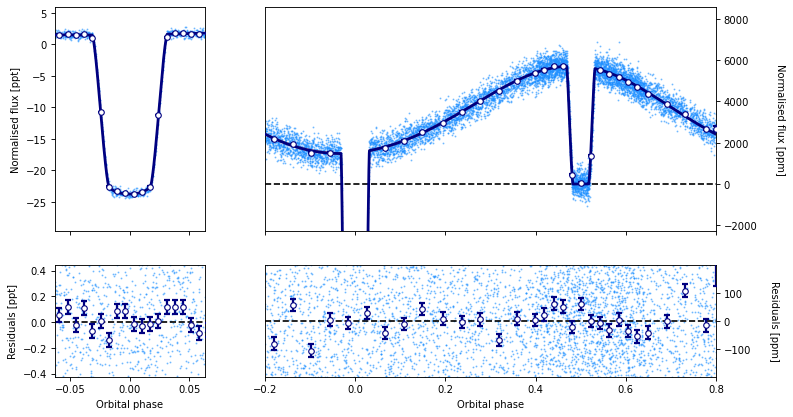

In [10]:
fit.plots(N=300).phase_folded_lc();

In [11]:
fit.diagnostics()

dataset,n,p2p_ppm,err_ppm,sigma_w_ppm,p2p_over_err,p2p_over_total,beta_8,beta_16,beta_32,beta_64,beta_128
str3,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
LRS,8379,354.6385200572045,285.39549999999997,233.35202527256257,1.2426212748876717,0.9619891442003146,1.1069403491591676,1.2169185501201518,1.350347155876614,1.406998339399113,1.5712543042567482


`summary()` adds the phase-curve quantities: the dayside flux `fp` (at the
eclipse), the nightside flux `fnight` (at the transit, $f_p - 2C_1$), the
peak-to-trough amplitude `pcamp` and the eastward offset of the maximum
before the eclipse `pcoffset`. The second-order terms are needed: the
evidence prefers them by Δln Z ≈ 90.

## 6. Comparison with Bell et al. (2024)

| | jstark | Bell et al., Eureka! v1 (fiducial) |
| --- | --- | --- |
| Transit depth (ppm) | 24,683 ± 48 | |
| Dayside $F_\mathrm{day}$ (ppm) | 5696 ± 19 | 5752 ± 19 |
| Nightside $F_\mathrm{night}$ (ppm) | 1518 ± 39 | 1636 ± 37 |
| Amplitude (ppm) | 4234 ± 35 | 4180 ± 33 |
| Offset (deg east) | 6.70 ± 0.39 | 7.34 ± 0.38 |

The shape of the phase curve (amplitude, offset) agrees. The dayside is
within 2σ. The nightside is lower by 118 ppm (2.2σ).

<div class="alert alert-info">

**Where the nightside difference comes from**

Bell et al. published four reductions of these data (Eureka! v1 and v2,
SPARTA, TEATRO), and their nightsides alone span ~170 ppm (1570-1739 ppm
when fitted with the same model). Fitting their Eureka! v1 light curve with
jstark's fitter reproduces their published values (dayside −1, nightside
+12 ppm), so the fitter is not the cause. Comparing the light curves
directly (ratio of ours to theirs, same model), jstark − Eureka! v1 is
−32 ± 16 ppm on the dayside and −100 ± 19 ppm on the nightside;
against SPARTA and TEATRO the nightside differs by −64 ppm. The
remaining nightside gap splits into:

* about 25 ppm from Stage 1 (jstark against the official Stage 1);
* 20-40 ppm from the ramps at the start of each exposure (removing a
  further 0.5-2 h after each exposure start moves it by that much);
* the rest is comparable to the spread among the published reductions.

The cleaner's background subtraction plays no role (`background=False`
gives the same light curves to 2 × 10⁻⁶). The transit depth now agrees with
Eureka! v1, v2 and SPARTA (+16 to +39 ppm, within 1.6σ); with `rscd` it was
deeper by 79-97 ppm.

</div>

## 7. Summary

| Stage | MIRI default | Evidence |
| --- | --- | --- |
| Stage 1 | official TSO recipe: `emicorr`, `lastframe`, `reset`, `dark_current`; no `firstframe`, `rscd`, `refpix` | `rscd` deepened the transit by 55 ppm against the official Stage 1 |
| Stage 1 | all usable groups fitted | GJ 3929: later ramp starts only cost precision |
| Cleaning | integration-level background (`background=True`) | no effect on the light curves; the extractor's local background absorbs it |
| Extraction | 5-12 µm; one PSF per visit (`VisitExtractor`) | per-exposure PSFs gave −2.5 / +0.4 ppt steps; one PSF gives the box-flux steps |
| Fitting | concatenate exposures; ramp; 2nd-order phase curve | Δln Z ≈ 90 for second order |
| Comparison | convert band edges across the 2024 wavelength calibration | dayside gap 106 → 48 ppm |